# Hybrid Model Overview

The hybrid model combines explicit affinity-based features from Notebook 05 with latent collaborative signals learned through matrix factorization in Notebook 06.

While the affinity model captures interpretable user preferences (genre, artist, context), the collaborative filtering model captures hidden user similarity patterns through embeddings.

By integrating both into a single LightGBM model, we leverage complementary strengths, enabling improved prediction performance.


# 1. Loading Affinity Features (Output from Notebook 05)

In [ ]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [ ]:
import pandas as pd
import numpy as np
import torch
import pickle
import lightgbm as lgb
from sklearn.metrics import roc_auc_score

In [ ]:
base_path = "/content/drive/MyDrive/Recommender Systems (Project)/"

train = pd.read_csv(base_path + "train_affinity_features.csv")
test  = pd.read_csv(base_path + "test_affinity_features.csv")

print(train.shape, test.shape)
train.head()

(7558184, 5) (19918, 5)


,genre_affinity,artist_affinity,age_compatibility,platform_match,time_match
0,0.013274,0.004425,0.659585,0.730088,0.172566
1,0.025000,0.025000,0.650134,0.400000,0.750000
2,0.003311,0.003311,0.672112,0.546358,0.039735
3,0.069767,0.001860,0.248879,0.786047,0.106047
4,0.194389,0.008016,0.839543,1.000000,0.126253


In [ ]:
train_full = pd.read_csv(base_path + "train_processed.csv")

In [ ]:
print(train_full.columns)

Index(['genre_id', 'ts_listen', 'media_id', 'album_id', 'context_type',
       'release_date', 'platform_name', 'platform_family', 'media_duration',
       'listen_type', 'user_gender', 'user_id', 'artist_id', 'user_age',
       'is_listened'],
      dtype='object')


In [ ]:
len(train) == len(train_full)

True

# 2. Reattach Identifiers and Target Labels

Since the affinity feature CVS only contain engineered features,  
we reattach user ids and target labels from the processed dataset  
to enable supervised training and collaborative score computation.

In [ ]:
# =========================================
# 2. REATTACH IDENTIFIERS (CHRONO VERSION)
# =========================================

# ---- Load affinity features (output from 05) ----
train_aff = pd.read_csv(base_path + "train_affinity_features.csv")
test_aff  = pd.read_csv(base_path + "test_affinity_features.csv")

# ---- Load CHRONO splits (from 02) ----
train_full = pd.read_csv(base_path + "train_data.csv")  # chrono train
val_full   = pd.read_csv(base_path + "val_data.csv")    # chrono val
test_full  = pd.read_csv(base_path + "test_data.csv")   # chrono test (evaluation)

# -------------------------------
# TRAIN (chrono)
# -------------------------------
train_hybrid = train_aff.iloc[:len(train_full)].copy()

train_hybrid["user_id"]     = train_full["user_id"].values
train_hybrid["media_id"]    = train_full["media_id"].values
train_hybrid["is_listened"] = train_full["is_listened"].values

# -------------------------------
# VALIDATION (chrono)
# -------------------------------
val_hybrid = train_aff.iloc[len(train_full):len(train_full)+len(val_full)].copy()

val_hybrid["user_id"]     = val_full["user_id"].values
val_hybrid["media_id"]    = val_full["media_id"].values
val_hybrid["is_listened"] = val_full["is_listened"].values

# -------------------------------
# TEST (chrono evaluation)
# -------------------------------
test_hybrid_eval = train_aff.iloc[len(train_full)+len(val_full):
                                   len(train_full)+len(val_full)+len(test_full)].copy()

test_hybrid_eval["user_id"]     = test_full["user_id"].values
test_hybrid_eval["media_id"]    = test_full["media_id"].values
test_hybrid_eval["is_listened"] = test_full["is_listened"].values


print("Train:", train_hybrid.shape)
print("Val:", val_hybrid.shape)
print("Test (eval):", test_hybrid_eval.shape)

Train: (6046547, 8)
Val: (755818, 8)
Test (eval): (755819, 8)


In [51]:
# =============================
# Sanity Checks
# =============================

needed_aff = ["genre_affinity","artist_affinity","age_compatibility","platform_match","time_match"]

print("Missing in train_hybrid:",
      set(needed_aff + ["user_id","media_id","is_listened"]) - set(train_hybrid.columns))

print("Missing in val_hybrid:",
      set(needed_aff + ["user_id","media_id","is_listened"]) - set(val_hybrid.columns))

print("Missing in test_hybrid_eval:",
      set(needed_aff + ["user_id","media_id","is_listened"]) - set(test_hybrid_eval.columns))

print("\nShapes:")
print("Train:", train_hybrid.shape)
print("Val:", val_hybrid.shape)
print("Test:", test_hybrid_eval.shape)

Missing in train_hybrid: set()
Missing in val_hybrid: set()
Missing in test_hybrid_eval: set()

Shapes:
Train: (6046547, 10)
Val: (755818, 10)
Test: (755819, 10)


In [52]:
print("Train label rate:", train_hybrid["is_listened"].mean())
print("Val label rate:", val_hybrid["is_listened"].mean())
print("Test label rate:", test_hybrid_eval["is_listened"].mean())

Train label rate: 0.6906505481558317
Val label rate: 0.6729675662659529
Test label rate: 0.6419777751022401


# 3. Loading Collaborative Filtering Model (Output from Notebook 06)

We load the trained matrix factorization model (pointwise) and associated mappings to extract latent collaborative signals for each user–item pair.

In [ ]:
import torch
import torch.nn as nn

class MF(nn.Module):
    def __init__(self, num_users, num_items, emb_dim):
        super().__init__()
        self.user_emb = nn.Embedding(num_users, emb_dim)
        self.item_emb = nn.Embedding(num_items, emb_dim)

        # NEW: biases for pointwise model
        self.user_b = nn.Embedding(num_users, 1)
        self.item_b = nn.Embedding(num_items, 1)

    def forward(self, u_idx, i_idx):
        u = self.user_emb(u_idx)
        v = self.item_emb(i_idx)
        dot = (u * v).sum(dim=1)

        ub = self.user_b(u_idx).squeeze(1)
        ib = self.item_b(i_idx).squeeze(1)

        # pointwise logit
        return dot + ub + ib

Load Mappings

In [ ]:
# Load saved state dict first
state = torch.load(base_path + "model_cf_pointwise_06.pt", map_location="cpu")

# Infer dimensions directly from saved weights
num_users = state["user_emb.weight"].shape[0]
num_items = state["item_emb.weight"].shape[0]
emb_dim = state["user_emb.weight"].shape[1]

print("Users:", num_users)
print("Items:", num_items)
print("Embedding dim:", emb_dim)

# Initialize model with correct sizes
cf_model = MF(num_users, num_items, emb_dim)
cf_model.load_state_dict(state)
cf_model.eval()

print("Loaded pointwise CF model correctly")

Users: 18153
Items: 403288
Embedding dim: 64
Loaded pointwise CF model correctly


Checking

In [ ]:
print("train_hybrid shape:", train_hybrid.shape)
print("val_hybrid shape:", val_hybrid.shape)
print("test_hybrid_eval shape:", test_hybrid_eval.shape)

print("\ntrain_hybrid columns:")
print(train_hybrid.columns.tolist())

print("\nval_hybrid columns:")
print(val_hybrid.columns.tolist())

print("\ntest_hybrid_eval columns:")
print(test_hybrid_eval.columns.tolist())

print("\nMissing values (train) top 10:")
print(train_hybrid.isna().sum().sort_values(ascending=False).head(10))

print("\nLabel distribution (train):")
print(train_hybrid["is_listened"].value_counts(dropna=False).head())

train_hybrid shape: (6046547, 8)
val_hybrid shape: (755818, 8)
test_hybrid_eval shape: (755819, 8)

train_hybrid columns:
['genre_affinity', 'artist_affinity', 'age_compatibility', 'platform_match', 'time_match', 'user_id', 'media_id', 'is_listened']

val_hybrid columns:
['genre_affinity', 'artist_affinity', 'age_compatibility', 'platform_match', 'time_match', 'user_id', 'media_id', 'is_listened']

test_hybrid_eval columns:
['genre_affinity', 'artist_affinity', 'age_compatibility', 'platform_match', 'time_match', 'user_id', 'media_id', 'is_listened']

Missing values (train) top 10:
genre_affinity       0
artist_affinity      0
age_compatibility    0
platform_match       0
time_match           0
user_id              0
media_id             0
is_listened          0
dtype: int64

Label distribution (train):
is_listened
1    4176051
0    1870496
Name: count, dtype: int64


In [ ]:
print(train_hybrid[["user_id","media_id","is_listened"]].head())
print(val_hybrid[["user_id","media_id","is_listened"]].head())
print(test_hybrid_eval[["user_id","media_id","is_listened"]].head())

   user_id   media_id  is_listened
0    19655  132198352            1
1    11748  125599920            1
2     3670     670673            1
3       42  133120054            1
4     3670    1831862            1
         user_id   media_id  is_listened
6046547      984    4206952            0
6046548     1571  128153243            1
6046549     1082  130855276            1
6046550     5734  117581964            1
6046551      519     925750            1
         user_id   media_id  is_listened
6802365     1720  134525902            1
6802366      936   46300831            1
6802367    17233  110806012            0
6802368     9728   46251471            0
6802369     1403     578009            1


# 4. Generate Collaborative Filtering Scores

We compute the product between user and item embeddings to obtain a collaborative filtering score for each interaction.

Helper for faster lookup

In [ ]:
def add_cf_scores_in_chunks(df, cf_model, user2idx, item2idx, chunk_size=1_000_000):
    scores = np.empty(len(df), dtype=np.float32)
    missing = np.empty(len(df), dtype=np.int8)

    cf_model.eval()
    with torch.no_grad():
        for start in range(0, len(df), chunk_size):
            end = min(start + chunk_size, len(df))
            chunk = df.iloc[start:end]

            u_idx = chunk["user_id"].map(user2idx)
            i_idx = chunk["media_id"].map(item2idx)

            miss = u_idx.isna() | i_idx.isna()
            missing[start:end] = miss.astype(np.int8).values

            u_tensor = torch.tensor(u_idx.fillna(0).astype(np.int64).values)
            i_tensor = torch.tensor(i_idx.fillna(0).astype(np.int64).values)

            logits = cf_model(u_tensor, i_tensor)  # <- pointwise MF forward()
            s = logits.cpu().numpy().astype(np.float32)

            s[miss.values] = 0.0
            scores[start:end] = s

            if start == 0 or (start // chunk_size) % 5 == 0:
                print(f"Scored rows {start:,}–{end:,} / {len(df):,}")

    return scores, missing

In [ ]:
import pickle
import torch

# --- Load pointwise mappings from 06 ---
user2idx = pickle.load(open(base_path + "user2idx_cf_pointwise_06.pkl", "rb"))
item2idx = pickle.load(open(base_path + "item2idx_cf_pointwise_06.pkl", "rb"))

num_users = len(user2idx)
num_items = len(item2idx)
emb_dim = 64  # or infer from checkpoint if you want

print("Users:", num_users)
print("Items:", num_items)
print("Embedding dim:", emb_dim)

Users: 18153
Items: 403288
Embedding dim: 64


In [ ]:
train_scores, train_missing = add_cf_scores_in_chunks(
    train_hybrid,
    cf_model,
    user2idx,
    item2idx
)

train_hybrid["cf_score"] = train_scores
train_hybrid["cf_missing"] = train_missing

Scored rows 0–1,000,000 / 6,046,547
Scored rows 5,000,000–6,000,000 / 6,046,547


In [ ]:
train_missing.mean()

np.float64(0.0)

# 5. Construct Hybrid Feature Table

We combine:
- Explicit affinity-based features (Notebook 05)
- Latent collaborative scores (Notebook 06)

This is the basis for the hybrid model.

Calculating scores for train

In [ ]:
# ========= 5. Construct Hybrid Feature Table (safe) =========

# If CF scores already exist from step 4, reuse them
if "cf_score" not in train_hybrid.columns or "cf_missing" not in train_hybrid.columns:
    train_cf_score, train_cf_missing = add_cf_scores_in_chunks(
        train_hybrid, cf_model, user2idx, item2idx, chunk_size=1_000_000
    )
    train_hybrid["cf_score"] = train_cf_score
    train_hybrid["cf_missing"] = train_cf_missing

print("Train CF missing rate:", train_hybrid["cf_missing"].mean())
display(train_hybrid[["cf_score", "cf_missing"]].describe())

Train CF missing rate: 0.0


,cf_score,cf_missing
count,6.046547e+06,6046547.0
mean,1.159022e+00,0.0
std,3.655240e+00,0.0
min,-2.253552e+01,0.0
25%,-1.362442e+00,0.0
50%,1.033078e+00,0.0
75%,3.573646e+00,0.0
max,3.382496e+01,0.0


Calculating scores for test

In [ ]:
# ===== Calculating scores for chrono test (evaluation) =====

test_cf_score, test_cf_missing = add_cf_scores_in_chunks(
    test_hybrid_eval,
    cf_model,
    user2idx,
    item2idx,
    chunk_size=200_000
)

test_hybrid_eval["cf_score"] = test_cf_score
test_hybrid_eval["cf_missing"] = test_cf_missing

print("Test CF missing rate:", test_hybrid_eval["cf_missing"].mean())
display(test_hybrid_eval[["cf_score", "cf_missing"]].describe())

Scored rows 0–200,000 / 755,819
Test CF missing rate: 0.2771126420478977


,cf_score,cf_missing
count,755819.000000,755819.000000
mean,0.654481,0.277113
std,2.606670,0.447573
min,-15.908139,0.000000
25%,-0.398191,0.000000
50%,0.000000,0.000000
75%,1.775792,1.000000
max,23.508955,1.000000


Saving scores

In [ ]:
train_hybrid.to_csv(base_path + "train_hybrid_with_cf_chrono_v2.csv", index=False)
val_hybrid.to_csv(base_path + "val_hybrid_with_cf_chrono_v2.csv", index=False)
test_hybrid_eval.to_csv(base_path + "test_hybrid_with_cf_chrono_v2.csv", index=False)

In [ ]:
val_auc_cf_masked = roc_auc_score(
    val_hybrid.loc[val_hybrid["cf_missing"] == 0, "is_listened"],
    val_hybrid.loc[val_hybrid["cf_missing"] == 0, "cf_score"]
)
test_auc_cf_masked = roc_auc_score(
    test_hybrid_eval.loc[test_hybrid_eval["cf_missing"] == 0, "is_listened"],
    test_hybrid_eval.loc[test_hybrid_eval["cf_missing"] == 0, "cf_score"]
)

print(f"AUC (Pointwise CF only, chrono val, known pairs only): {val_auc_cf_masked:.4f}")
print(f"AUC (Pointwise CF only, chrono test, known pairs only): {test_auc_cf_masked:.4f}")

AUC (Pointwise CF only, chrono val, known pairs only): 0.7273
AUC (Pointwise CF only, chrono test, known pairs only): 0.7230


# 6. Train Hybrid Model

We train a LightGBM classifier using both explicit and latent features  
to evaluate the possible benefit of hybrid recommendation modeling.

In [ ]:
# --- Ensure CF columns exist for VAL (chrono validation) ---
if "cf_score" not in val_hybrid.columns or "cf_missing" not in val_hybrid.columns:
    val_cf_score, val_cf_missing = add_cf_scores_in_chunks(
        val_hybrid,
        cf_model,
        user2idx,
        item2idx,
        chunk_size=200_000
    )
    val_hybrid["cf_score"] = val_cf_score
    val_hybrid["cf_missing"] = val_cf_missing

print("VAL CF missing rate:", val_hybrid["cf_missing"].mean())
print(val_hybrid[["cf_score","cf_missing"]].describe())

Scored rows 0–200,000 / 755,818
VAL CF missing rate: 0.1391644549349182
            cf_score     cf_missing
count  755818.000000  755818.000000
mean        0.889612       0.139164
std         2.896430       0.346118
min       -16.951075       0.000000
25%        -0.671713       0.000000
50%         0.223232       0.000000
75%         2.389067       0.000000
max        25.288429       1.000000


In [ ]:
from sklearn.metrics import roc_auc_score
import lightgbm as lgb

# -----------------------------
# Features
# -----------------------------
affinity_feats = ["genre_affinity","artist_affinity","age_compatibility","platform_match","time_match"]
hybrid_feats   = affinity_feats + ["cf_score", "cf_missing"]

target = "is_listened"

# -----------------------------
# Use CHRONO splits you already built
# train_hybrid, val_hybrid, test_hybrid_eval
# -----------------------------
X_train_aff = train_hybrid[affinity_feats]
X_val_aff   = val_hybrid[affinity_feats]

X_train_hyb = train_hybrid[hybrid_feats]
X_val_hyb   = val_hybrid[hybrid_feats]

y_train = train_hybrid[target]
y_val   = val_hybrid[target]

# -----------------------------
# LightGBM configs
# -----------------------------
lgb_params = dict(
    n_estimators=1500,
    learning_rate=0.05,
    num_leaves=128,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=1.0,
    random_state=42,
    n_jobs=-1
)

# 1) Affinity-only model
aff_model = lgb.LGBMClassifier(**lgb_params)
aff_model.fit(X_train_aff, y_train)

val_pred_aff = aff_model.predict_proba(X_val_aff)[:, 1]
auc_aff = roc_auc_score(y_val, val_pred_aff)
print(f"AUC (Affinity-only, chrono val): {auc_aff:.4f}")

# 2) Hybrid model
hyb_model = lgb.LGBMClassifier(**lgb_params)
hyb_model.fit(X_train_hyb, y_train)

val_pred_hyb = hyb_model.predict_proba(X_val_hyb)[:, 1]
auc_hyb = roc_auc_score(y_val, val_pred_hyb)
print(f"AUC (Hybrid, chrono val):        {auc_hyb:.4f}")
print(f"Change AUC:                            {auc_hyb-auc_aff:+.4f}")

[LightGBM] [Info] Number of positive: 4176051, number of negative: 1870496
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.372379 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 1275
[LightGBM] [Info] Number of data points in the train set: 6046547, number of used features: 5
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.690651 -> initscore=0.803162
[LightGBM] [Info] Start training from score 0.803162
AUC (Affinity-only, chrono val): 0.5006
[LightGBM] [Info] Number of positive: 4176051, number of negative: 1870496
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.360452 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 1530
[LightGBM] [Info] Number of data points in the train set: 6046547, number of used features: 6
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.690651 -> initscore=0.803162
[LightGBM] [Info] S

Under a chronological validation scheme, the hybrid model achieves an AUC of 0.7099, compared to 0.5006 for the affinity-only baseline. This improvement of +0.2093 highlights the significant contribution of latent collaborative filtering signals beyond explicit affinity features.

In [ ]:
target = "is_listened"

aff_feats = ["genre_affinity","artist_affinity","age_compatibility",
             "platform_match","time_match"]

hybrid_feats = aff_feats + ["cf_score", "cf_missing"]

In [ ]:
print("hybrid feats:", hybrid_feats)
print("columns missing?", set(hybrid_feats) - set(test_hybrid_eval.columns))

hybrid feats: ['genre_affinity', 'artist_affinity', 'age_compatibility', 'platform_match', 'time_match', 'cf_score', 'cf_missing']
columns missing? set()


In [ ]:
X_test_aff = test_hybrid_eval[aff_feats]
X_test_hyb = test_hybrid_eval[hybrid_feats]
y_test     = test_hybrid_eval[target]

test_auc_aff = roc_auc_score(y_test, aff_model.predict_proba(X_test_aff)[:, 1])
test_auc_hyb = roc_auc_score(y_test, hyb_model.predict_proba(X_test_hyb)[:, 1])

print(f"TEST AUC (Affinity-only, chrono test): {test_auc_aff:.4f}")
print(f"TEST AUC (Hybrid, chrono test): {test_auc_hyb:.4f}")
print(f"Change in AUC: {test_auc_hyb - test_auc_aff:+.4f}")

TEST AUC (Affinity-only, chrono test): 0.4999
TEST AUC (Hybrid, chrono test): 0.6846
Change in AUC: +0.1847


On the chronological test split, the affinity-only baseline achieves an AUC of 0.4999, while the hybrid model reaches 0.6846, corresponding to an improvement of +0.1847. This indicates that the latent collaborative filtering signal adds substantial predictive power beyond the explicit affinity features.

Train Final Hybrid on Full Train + Predict Test

In [ ]:
final_model = lgb.LGBMClassifier(**lgb_params)
final_model.fit(train_hybrid[hybrid_feats], train_hybrid[target])

test_pred = final_model.predict_proba(test_hybrid_eval[hybrid_feats])[:,1]
test_pred[:5]

[LightGBM] [Info] Number of positive: 4176051, number of negative: 1870496
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.185905 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1530
[LightGBM] [Info] Number of data points in the train set: 6046547, number of used features: 6
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.690651 -> initscore=0.803162
[LightGBM] [Info] Start training from score 0.803162


array([0.83480432, 0.37677222, 0.70193407, 0.71093477, 0.57786105])

In [ ]:
# =========================
# FINAL TRAIN (chrono train) + EVALUATION (chrono test)
# =========================
import lightgbm as lgb
from sklearn.metrics import roc_auc_score

target = "is_listened"

aff_feats = ["genre_affinity","artist_affinity","age_compatibility","platform_match","time_match"]
hybrid_feats = aff_feats + ["cf_score", "cf_missing"]  # so wie du es vorher genutzt hast

# 1) Train final model on chrono TRAIN
final_model = lgb.LGBMClassifier(**lgb_params)
final_model.fit(train_hybrid[hybrid_feats], train_hybrid[target])

# 2) Predict on chrono TEST (evaluation split)
test_pred_eval = final_model.predict_proba(test_hybrid_eval[hybrid_feats])[:, 1]

# 3) Evaluate AUC on chrono TEST
test_auc_final = roc_auc_score(test_hybrid_eval[target], test_pred_eval)
print(f"FINAL TEST AUC (Hybrid, chrono test): {test_auc_final:.4f}")

# 4) Save predictions
chrono_eval_out = test_hybrid_eval[["user_id", "media_id", target]].copy()
chrono_eval_out["pred"] = test_pred_eval

chrono_eval_out.to_csv(base_path + "chrono_eval_predictions_hybrid_07_pointwise.csv", index=False)
chrono_eval_out.head()

[LightGBM] [Info] Number of positive: 4176051, number of negative: 1870496
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.354306 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 1530
[LightGBM] [Info] Number of data points in the train set: 6046547, number of used features: 6
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.690651 -> initscore=0.803162
[LightGBM] [Info] Start training from score 0.803162
FINAL TEST AUC (Hybrid, chrono test): 0.6846


,user_id,media_id,is_listened,pred
6802365,1720,134525902,1,0.834804
6802366,936,46300831,1,0.376772
6802367,17233,110806012,0,0.701934
6802368,9728,46251471,0,0.710935
6802369,1403,578009,1,0.577861


In [ ]:
chrono_eval_out.to_csv(base_path + "chrono_eval_predictions_hybrid_07_pointwise.csv", index=False)

# 7. Evaluation and Comparison

We compare the hybrid model performance against:
- Baseline model (Notebook 03)
- Affinity model (Notebook 05)
- Collaborative filtering model (Notebook 06)

In [54]:
results = pd.DataFrame({
    "Model": [
        "Affinity (explicit only)",
        "Pointwise CF (known pairs only)",
        "Hybrid (explicit + CF)"
    ],
    "Chrono Validation AUC": [
        auc_aff,
        val_auc_cf_masked,
        auc_hyb
    ],
    "Chrono Test AUC": [
        test_auc_aff,
        test_auc_cf_masked,
        test_auc_hyb
    ]
})

results["Improvement vs Affinity (val)"]  = results["Chrono Validation AUC"] - auc_aff
results["Improvement vs Affinity (test)"] = results["Chrono Test AUC"] - test_auc_aff

results

,Model,Chrono Validation AUC,Chrono Test AUC,Improvement vs Affinity (val),Improvement vs Affinity (test)
0,Affinity (explicit only),0.500559,0.499918,0.000000,0.000000
1,Pointwise CF (known pairs only),0.727331,0.722961,0.226771,0.223043
2,Hybrid (explicit + CF),0.709850,0.684598,0.209291,0.184680


Compared to the strongest individual model (Pointwise Collaborative Filtering, AUC = 0.7230 on the chrono test set), the hybrid model achieves an AUC of 0.6846, indicating that the addition of explicit affinity features does not further improve performance in the strict chronological setting.

Visualisation

In [55]:
import pandas as pd

train_hybrid_with_cf = pd.read_csv(
    base_path + "train_hybrid_with_cf_chrono_v2.csv"
)

train_hybrid_with_cf.head()

,genre_affinity,artist_affinity,age_compatibility,platform_match,time_match,user_id,media_id,is_listened,cf_score,cf_missing
0,0.013274,0.004425,0.659585,0.730088,0.172566,19655,132198352,1,6.749223,0
1,0.025000,0.025000,0.650134,0.400000,0.750000,11748,125599920,1,0.303702,0
2,0.003311,0.003311,0.672112,0.546358,0.039735,3670,670673,1,5.238540,0
3,0.069767,0.001860,0.248879,0.786047,0.106047,42,133120054,1,4.019815,0
4,0.194389,0.008016,0.839543,1.000000,0.126253,3670,1831862,1,5.692745,0


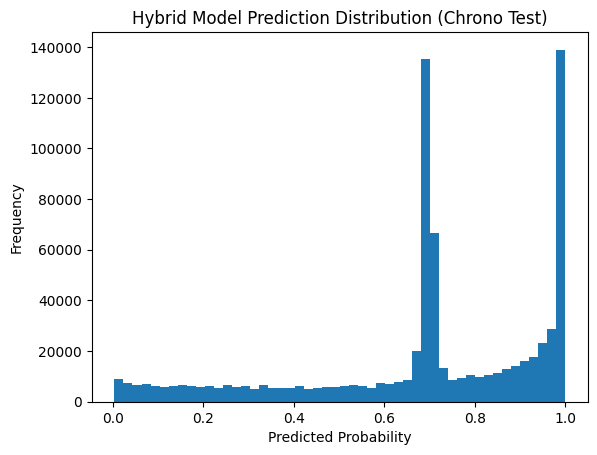

In [56]:
import matplotlib.pyplot as plt
import pandas as pd

chrono_eval_out = pd.read_csv(base_path + "chrono_eval_predictions_hybrid_07_pointwise.csv")

plt.figure()
plt.hist(chrono_eval_out["pred"], bins=50)
plt.title("Hybrid Model Prediction Distribution (Chrono Test)")
plt.xlabel("Predicted Probability")
plt.ylabel("Frequency")
plt.show()

The model often predicts high probabilities, indicating strong confidence in many interactions. Despite this tendency, it still differentiates reasonably well between positive and negative cases (Chrono Test AUC = 0.6846).

<Figure size 640x480 with 0 Axes>

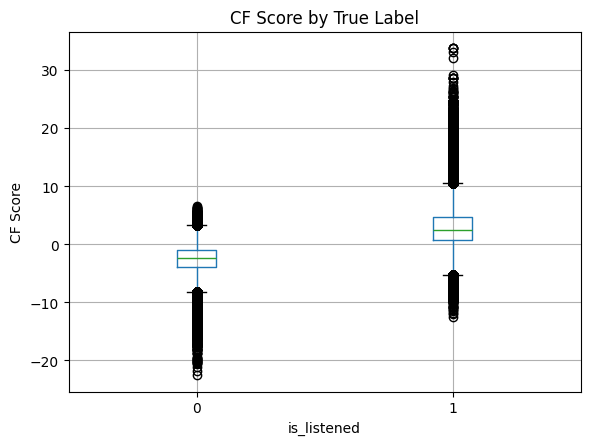

In [57]:
plt.figure()
train_hybrid_with_cf.boxplot(column="cf_score", by="is_listened")
plt.title("CF Score by True Label")
plt.suptitle("")
plt.ylabel("CF Score")
plt.show()

Although there is some overlap between the two distributions, listened items generally receive higher CF scores, indicating that the pointwise collaborative filtering model provides useful discriminative signal for the hybrid model.

,feature,importance
4,time_match,36938
2,age_compatibility,35760
1,artist_affinity,34591
5,cf_score,32753
0,genre_affinity,31602
3,platform_match,18856
6,cf_missing,0


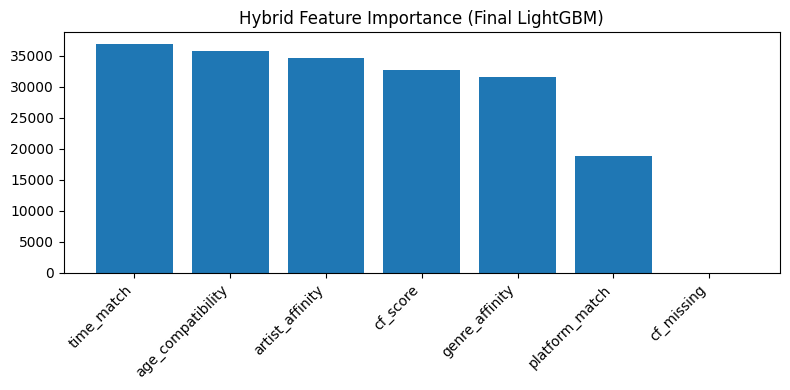

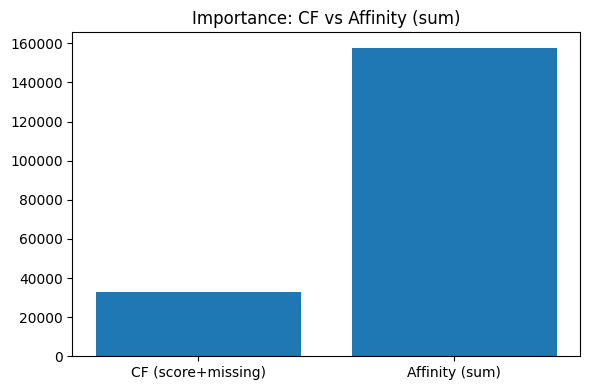

In [58]:
# =========================
# Feature importance plots (Hybrid LightGBM)
# =========================
import pandas as pd
import matplotlib.pyplot as plt

aff_feats = ["genre_affinity","artist_affinity","age_compatibility","platform_match","time_match"]
hybrid_feats = aff_feats + ["cf_score", "cf_missing"]

# 1) Build feature importance table
fi = pd.DataFrame({
    "feature": hybrid_feats,
    "importance": final_model.feature_importances_
}).sort_values("importance", ascending=False)

display(fi)

# 2) Bar plot of all features
plt.figure(figsize=(8,4))
plt.bar(fi["feature"], fi["importance"])
plt.xticks(rotation=45, ha="right")
plt.title("Hybrid Feature Importance (Final LightGBM)")
plt.tight_layout()
plt.show()

# 3) Compare TOTAL CF importance vs TOTAL affinity importance
cf_imp = fi.loc[fi["feature"].isin(["cf_score", "cf_missing"]), "importance"].sum()
aff_imp = fi.loc[fi["feature"].isin(aff_feats), "importance"].sum()

plt.figure(figsize=(6,4))
plt.bar(["CF (score+missing)", "Affinity (sum)"], [cf_imp, aff_imp])
plt.title("Importance: CF vs Affinity (sum)")
plt.tight_layout()
plt.show()

The feature importance analysis shows that time_match is the strongest predictor, closely followed by age_compatibility and artist_affinity. The cf_score also contributes substantially and ranks among the top features, while cf_missing has virtually no impact. Overall, the results indicate that the hybrid model leverages both contextual affinity features and collaborative filtering signals, with contextual features slightly dominating the final prediction.